# Autoencoders

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/autoencoders/autoencoders-notebook.ipynb)

Companion notebook for the *Autoencoders* slides. Each idea is written first by hand
with NumPy, in small classes shaped like PyTorch's, and then with the PyTorch module that does the same job.

**Data:** the scikit-learn digits (1797 pictures of 8 × 8 pixels, $d = 64$, scaled to $[0, 1]$); the labels are used only to color plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from torch import nn
from torch.distributions import Normal, kl_divergence

RANDOM_STATE = 42
CODE_SIZE = 2
LEARNING_RATE = 0.1
STEPS = 3000

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)
X, labels = load_digits(return_X_y=True)
X = X / 16
X_train, X_test, labels_train, labels_test = train_test_split(
    X, labels, test_size=0.3, random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

## 1. The reconstruction loss

$J = \frac{1}{n}\sum_i \lVert \mathbf{x}_i - \hat{\mathbf{x}}_i \rVert^2$, the slide's example with two examples of 3 features.

In [2]:
x = np.array([[1.0, 0, 2], [0, 1, 1]])
x_hat = np.array([[0.8, 0.1, 1.7], [0.2, 0.9, 1.0]])
squared_norms = np.sum((x - x_hat) ** 2, axis=1)  # ||x_i - x_hat_i||^2 for each example
J = np.mean(squared_norms)  # (1/n) sum_i

# nn.MSELoss averages over the 3 features too; summing and dividing by n gives J
sum_of_squares = nn.MSELoss(reduction="sum")
torch_J = sum_of_squares(torch.from_numpy(x_hat), torch.from_numpy(x)) / len(x)
print(f"J = {J:.3f} | same result:", np.isclose(J, torch_J.item()))

J = 0.095 | same result: True


## 2. A linear autoencoder finds the PCA subspace

Encoder $\mathbf{z} = \mathbf{W}_1\mathbf{x}$, decoder $\hat{\mathbf{x}} = \mathbf{W}_2\mathbf{z}$ (no activation, centered data),
trained by gradient descent $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha\nabla_{\boldsymbol\theta} J$ with code size $q = 2$.
The NumPy classes copy the shape of `nn.Linear`, `nn.Tanh` and `nn.Sequential`; the autoencoder is an encoder followed by a decoder.

In [3]:
class Linear:
    """NumPy version of nn.Linear: x @ weight.T + bias."""

    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        self.weight = rng.normal(0, 0.1, (out_features, in_features))
        self.bias = np.zeros(out_features) if bias else None

    def forward(self, x: np.ndarray) -> np.ndarray:
        output = x @ self.weight.T
        if self.bias is not None:
            output = output + self.bias
        return output


class Tanh:
    """NumPy version of nn.Tanh."""

    def forward(self, x: np.ndarray) -> np.ndarray:
        return np.tanh(x)


class Sequential:
    """NumPy version of nn.Sequential: apply the layers in order."""

    def __init__(self, *layers):
        self.layers = layers

    def forward(self, x: np.ndarray) -> np.ndarray:
        for layer in self.layers:
            x = layer.forward(x)
        return x


class Autoencoder:
    """Encoder f_phi then decoder g_psi."""

    def __init__(self, encoder, decoder):
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x: np.ndarray) -> np.ndarray:
        z = self.encoder.forward(x)  # z = f_phi(x)
        x_hat = self.decoder.forward(z)  # x_hat = g_psi(z)
        return x_hat

Training by hand, with the gradients of $J$ written out.

In [4]:
mean = X_train.mean(axis=0)
X_centered = X_train - mean
d = X.shape[1]
linear_ae = Autoencoder(Linear(d, CODE_SIZE, bias=False), Linear(CODE_SIZE, d, bias=False))
W1 = linear_ae.encoder.weight
W2 = linear_ae.decoder.weight

torch_linear_ae = nn.Sequential(nn.Linear(d, CODE_SIZE, bias=False),
                                nn.Linear(CODE_SIZE, d, bias=False))
with torch.no_grad():  # same starting weights, copied before training
    torch_linear_ae[0].weight.copy_(torch.from_numpy(W1))
    torch_linear_ae[1].weight.copy_(torch.from_numpy(W2))

losses = []
for _ in range(STEPS):
    n = len(X_centered)
    Z = linear_ae.encoder.forward(X_centered)  # z = W1 x
    X_hat = linear_ae.decoder.forward(Z)  # x_hat = W2 z
    residual = X_hat - X_centered
    J = np.mean(np.sum(residual ** 2, axis=1))
    losses.append(J)
    grad_W2 = 2 * residual.T @ Z / n  # dJ/dW2
    grad_W1 = 2 * (residual @ W2).T @ X_centered / n  # dJ/dW1
    W1 -= LEARNING_RATE * grad_W1
    W2 -= LEARNING_RATE * grad_W2

In PyTorch, autograd gives the gradients and `torch.optim.SGD` makes the step. `nn.MSELoss` divides by $n \cdot d$, so we multiply by $d$ to get $J$.

In [5]:
X_centered_t = torch.from_numpy(X_centered)
optimizer = torch.optim.SGD(torch_linear_ae.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()
for _ in range(STEPS):
    optimizer.zero_grad()
    reconstruction = torch_linear_ae(X_centered_t)
    loss = d * loss_fn(reconstruction, X_centered_t)  # times d to get J
    loss.backward()
    optimizer.step()

same_W1 = np.allclose(W1, torch_linear_ae[0].weight.detach().numpy())
same_W2 = np.allclose(W2, torch_linear_ae[1].weight.detach().numpy())
print("same weights:", same_W1 and same_W2)

same weights: True


PCA, the non-neural reference, keeps the same subspace. The two codes can be rotated versions of each other,
so we compare the subspaces (their projection matrices), not the weights.

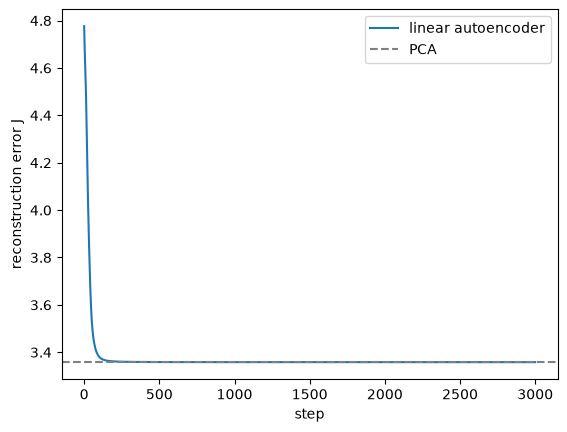

same error: True
same subspace: True


In [6]:
pca = PCA(n_components=CODE_SIZE).fit(X_train)
pca_reconstruction = pca.inverse_transform(pca.transform(X_train))
pca_error = np.mean(np.sum((pca_reconstruction - X_train) ** 2, axis=1))

plt.plot(losses, label="linear autoencoder")
plt.axhline(pca_error, color="gray", linestyle="--", label="PCA")
plt.xlabel("step")
plt.ylabel("reconstruction error J")
plt.legend()
plt.show()

Q, _ = np.linalg.qr(W2)
print("same error:", np.isclose(losses[-1], pca_error, rtol=1e-3))
print("same subspace:", np.allclose(Q @ Q.T, pca.components_.T @ pca.components_, atol=1e-3))

## 3. A nonlinear autoencoder

Layers $64 \to 64 \to 2 \to 64 \to 64$ with tanh, trained in PyTorch with `torch.optim.Adam`.
The encoder is the first half: $\mathbf{z} = g(\mathbf{W}\,g(\mathbf{W}\mathbf{x} + \mathbf{b}) + \mathbf{b})$.

In [7]:
class TorchAutoencoder(nn.Module):
    """Encoder f_phi then decoder g_psi."""

    def __init__(self, encoder: nn.Module, decoder: nn.Module):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat


encoder = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, CODE_SIZE), nn.Tanh())
decoder = nn.Sequential(nn.Linear(CODE_SIZE, 64), nn.Tanh(), nn.Linear(64, d))
autoencoder = TorchAutoencoder(encoder, decoder)
X_train_t = torch.from_numpy(X_train)
X_test_t = torch.from_numpy(X_test)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.003)
for _ in range(STEPS):
    optimizer.zero_grad()
    reconstruction = autoencoder(X_train_t)
    loss = d * loss_fn(reconstruction, X_train_t)
    loss.backward()
    optimizer.step()

The same network in NumPy, with the trained weights copied across, gives the same codes and reconstructions.

In [8]:
numpy_ae = Autoencoder(Sequential(Linear(d, 64), Tanh(), Linear(64, CODE_SIZE), Tanh()),
                       Sequential(Linear(CODE_SIZE, 64), Tanh(), Linear(64, d)))
pairs = [(numpy_ae.encoder, autoencoder.encoder), (numpy_ae.decoder, autoencoder.decoder)]
for numpy_part, torch_part in pairs:
    for numpy_layer, torch_layer in zip(numpy_part.layers, torch_part):
        if isinstance(torch_layer, nn.Linear):
            numpy_layer.weight = torch_layer.weight.detach().numpy()
            numpy_layer.bias = torch_layer.bias.detach().numpy()

codes = numpy_ae.encoder.forward(X_test)
reconstructions = numpy_ae.forward(X_test)
with torch.no_grad():
    torch_codes = autoencoder.encoder(X_test_t).numpy()
    torch_reconstructions = autoencoder(X_test_t).numpy()
print("same result:", np.allclose(codes, torch_codes)
      and np.allclose(reconstructions, torch_reconstructions))

ae_error = np.mean(np.sum((reconstructions - X_test) ** 2, axis=1))
pca_test_reconstruction = pca.inverse_transform(pca.transform(X_test))
pca_test_error = np.mean(np.sum((pca_test_reconstruction - X_test) ** 2, axis=1))
print(f"test reconstruction error with a code of 2: autoencoder {ae_error:.2f},",
      f"PCA {pca_test_error:.2f}")

same result: True
test reconstruction error with a code of 2: autoencoder 2.18, PCA 3.36


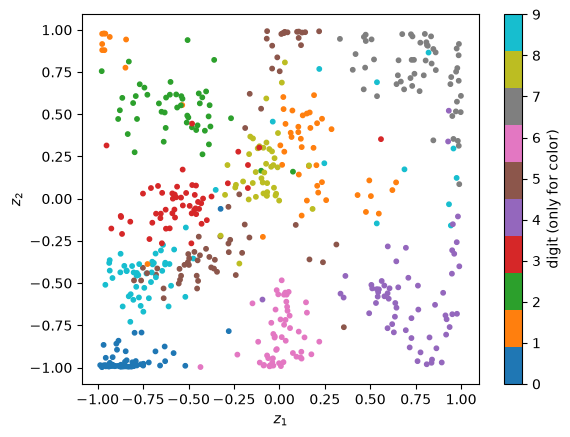

In [9]:
plt.scatter(codes[:, 0], codes[:, 1], c=labels_test, cmap="tab10", s=10)
plt.colorbar(label="digit (only for color)")
plt.xlabel("$z_1$")
plt.ylabel("$z_2$")
plt.show()

## 4. Spotting odd examples

$s(\mathbf{x}) = \lVert \mathbf{x} - g_{\boldsymbol\psi}(f_{\boldsymbol\phi}(\mathbf{x})) \rVert^2$: flag $\mathbf{x}$ if $s(\mathbf{x}) > \tau$.
The odd examples here are pictures of random noise; $\tau$ is the 99th percentile of the scores on training digits.

In [10]:
def score(images: np.ndarray) -> np.ndarray:
    reconstructions = numpy_ae.forward(images)  # g_psi(f_phi(x))
    return np.sum((images - reconstructions) ** 2, axis=1)  # s(x)


tau = np.percentile(score(X_train), 99)
noise_images = rng.uniform(0, 1, (50, d))
flagged_digits = np.mean(score(X_test) > tau)
flagged_noise = np.mean(score(noise_images) > tau)
print(f"flagged: {flagged_digits:.0%} of new digits, {flagged_noise:.0%} of noise pictures")

flagged: 6% of new digits, 100% of noise pictures


In PyTorch, `reduction="none"` keeps one squared error per pixel; summing each row gives the scores.

In [11]:
with torch.no_grad():
    squared_errors = nn.MSELoss(reduction="none")(autoencoder(X_test_t), X_test_t)
    torch_scores = squared_errors.sum(dim=1)
print("same result:", np.allclose(score(X_test), torch_scores.numpy()))

same result: True


## 5. Variational autoencoder: sampling the code

Reparameterization: $\mathbf{z} = \boldsymbol\mu + \boldsymbol\sigma \odot \boldsymbol\epsilon$, $\boldsymbol\epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$.
The randomness sits in $\boldsymbol\epsilon$, so autograd can still send gradients to $\boldsymbol\mu$ and $\boldsymbol\sigma$.

In [12]:
mu = np.array([1.0, -0.5])
sigma = np.array([0.5, 2.0])
epsilon = rng.normal(size=(100_000, 2))  # epsilon ~ N(0, I)
z = mu + sigma * epsilon

mu_t = torch.tensor(mu, requires_grad=True)
sigma_t = torch.tensor(sigma, requires_grad=True)
epsilon_t = torch.randn(100_000, 2)
z_t = mu_t + sigma_t * epsilon_t
z_t.sum().backward()
print("gradients reach mu and sigma:", mu_t.grad is not None and sigma_t.grad is not None)
both_match = True
for sample in [z, z_t.detach().numpy()]:
    mean_ok = np.allclose(sample.mean(axis=0), mu, atol=0.02)
    std_ok = np.allclose(sample.std(axis=0), sigma, atol=0.02)
    both_match = both_match and mean_ok and std_ok
print("both samples match mu and sigma (tolerance 0.02):", both_match)

gradients reach mu and sigma: True
both samples match mu and sigma (tolerance 0.02): True


The penalty is $\text{KL} = \sum_j \tfrac12(\mu_j^2 + \sigma_j^2 - 1 - \ln\sigma_j^2)$. PyTorch has it built in for two normal distributions.

In [13]:
kl_terms = 0.5 * (mu ** 2 + sigma ** 2 - 1 - np.log(sigma ** 2))  # one term per j
kl_by_hand = np.sum(kl_terms)
kl_torch = kl_divergence(Normal(mu_t, sigma_t), Normal(0.0, 1.0)).sum()
print(f"KL = {kl_by_hand:.3f} | same result:", np.isclose(kl_by_hand, kl_torch.item()))

KL = 1.750 | same result: True


## Exercises

1. Change `CODE_SIZE` to 10 in section 2. Does the linear autoencoder still match PCA?
2. Train the section 3 autoencoder on noisy copies `X_train_t + 0.1 * torch.randn_like(X_train_t)` with target `X_train_t` (denoising) and compare its error on noisy test digits.
3. In section 4, use the digits 0 to 4 as normal data and the digits 5 to 9 as odd ones. How many are flagged?